In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

PROJECT_DIR = "/content/drive/MyDrive/housing_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# download from Kaggle by code and find the CSV file
path = kagglehub.dataset_download("camnugent/california-housing-prices")
csv_files = glob.glob(f"{path}/**/*.csv", recursive=True)
print("Files found:", csv_files)

df = pd.read_csv(csv_files[0])
print("\nShape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

print("\nColumns and types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

print("\nocean_proximity counts:")
print(df["ocean_proximity"].value_counts())

target = "median_house_value"
print(f"\nTarget '{target}': min {df[target].min():,.0f} | max {df[target].max():,.0f}")
print("Rows at the maximum value (capped):", int((df[target] == df[target].max()).sum()))

print("\nSummary statistics:")
print(df.describe().round(2).T)

Mounted at /content/drive
Using Colab cache for faster access to the 'california-housing-prices' dataset.
Files found: ['/kaggle/input/california-housing-prices/housing.csv']

Shape: (20640, 10)

First 5 records:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       

Missing values:
                missing  percent
total_bedrooms      207      1.0 

Highest house value: 500,001 | rows at that value (capped): 965 (4.7%)
housing_median_age maximum: 52 | rows at that value: 1273
Target skewness: 0.98 



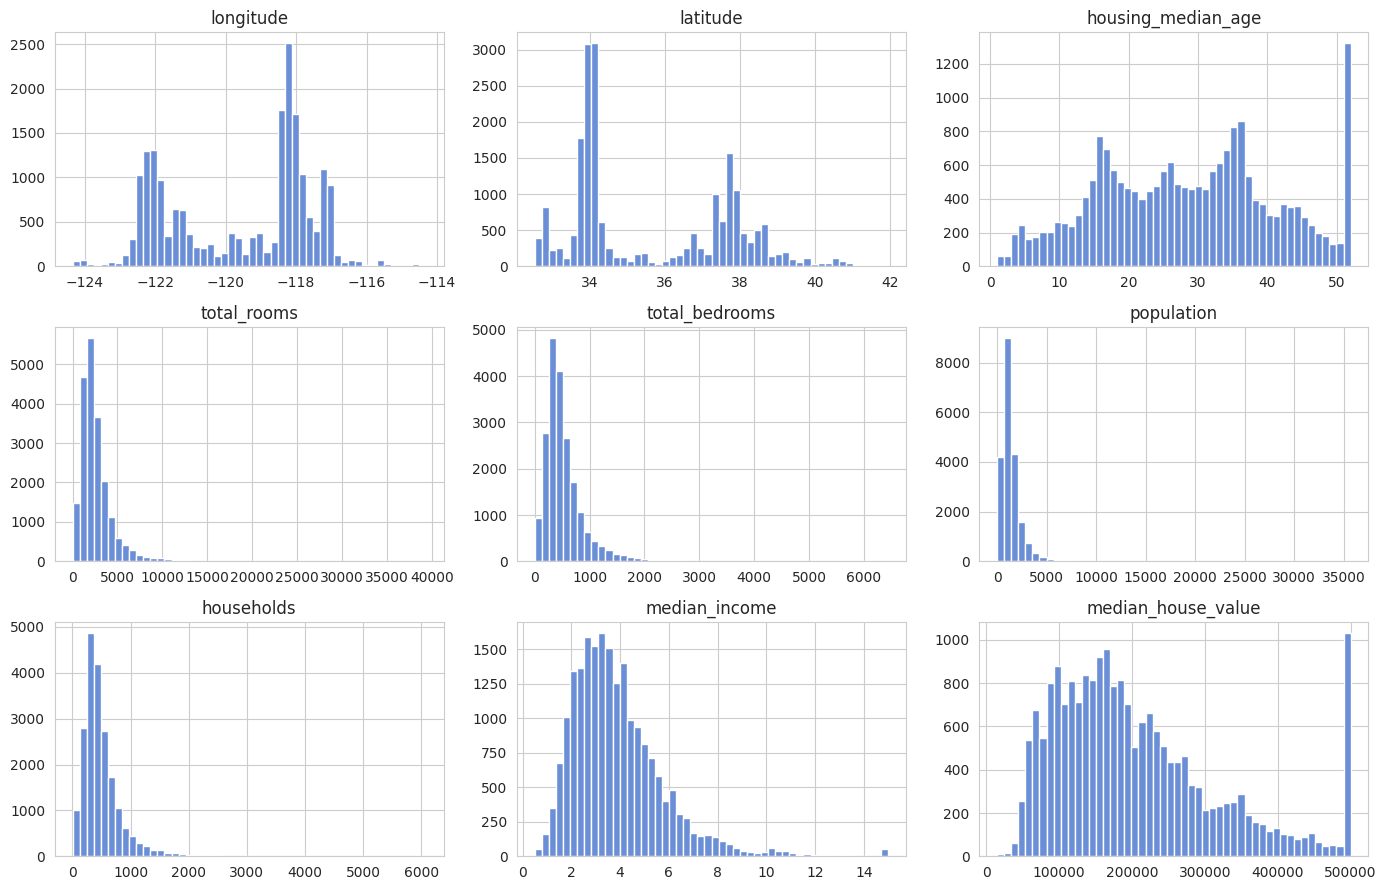

Removed 965 capped rows -> 19675 rows remain


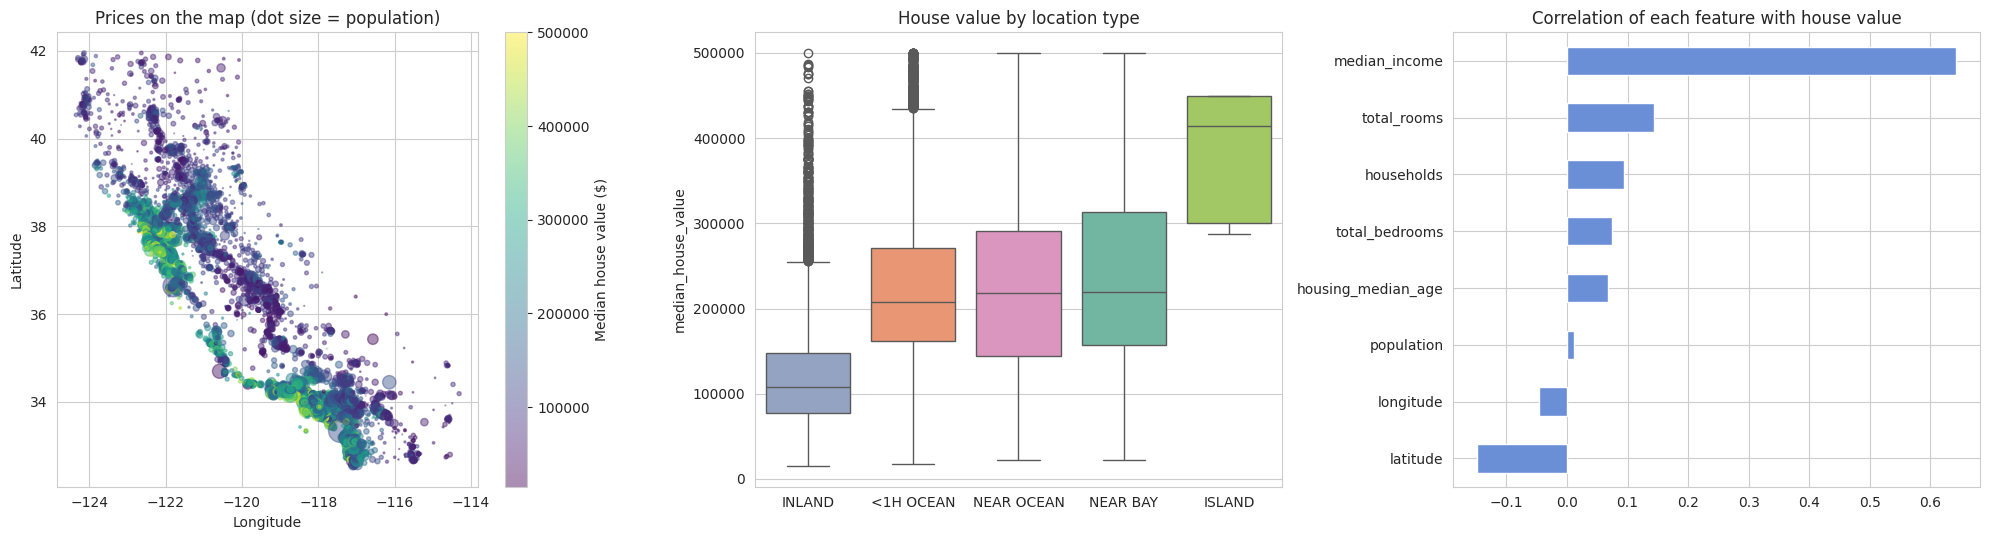

latitude             -0.148
longitude            -0.047
population            0.012
housing_median_age    0.068
total_bedrooms        0.075
households            0.095
total_rooms           0.143
median_income         0.643
Name: median_house_value, dtype: float64

Median house value by location type:
                 count    median
ocean_proximity                 
<1H OCEAN         8604  207650.0
INLAND            6524  108300.0
ISLAND               5  414700.0
NEAR BAY          2096  219850.0
NEAR OCEAN        2446  218250.0


In [ ]:
sns.set_style("whitegrid")
target = "median_house_value"
NUM = df.select_dtypes("number").columns.tolist()

# 1. data quality summary
print("Missing values:")
miss = df.isnull().sum()
print(pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(2)})[miss > 0], "\n")
cap = df[target].max()
print(f"Highest house value: {cap:,.0f} | rows at that value (capped): {(df[target] == cap).sum()} ({(df[target] == cap).mean():.1%})")
print(f"housing_median_age maximum: {df['housing_median_age'].max():.0f} | rows at that value: {(df['housing_median_age'] == df['housing_median_age'].max()).sum()}")
print("Target skewness:", round(df[target].skew(), 2), "\n")

# 2. distributions of every numeric column (before cleaning)
fig, ax = plt.subplots(3, 3, figsize=(14, 9))
for a, c in zip(ax.ravel(), NUM):
    a.hist(df[c].dropna(), bins=50, color="#6b8fd6"); a.set_title(c)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/distributions.png", dpi=150)
plt.show()

# 3. cleaning: remove the rows whose price is capped at the maximum
before = len(df)
df = df[df[target] < cap].reset_index(drop=True)
print(f"Removed {before - len(df)} capped rows -> {df.shape[0]} rows remain")
df.to_csv(f"{PROJECT_DIR}/housing_clean.csv", index=False)

# 4. exploration on the cleaned data: map, price by location type, correlation with price
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
sc = ax[0].scatter(df["longitude"], df["latitude"], c=df[target], s=df["population"] / 120, cmap="viridis", alpha=0.45)
plt.colorbar(sc, ax=ax[0], label="Median house value ($)")
ax[0].set_title("Prices on the map (dot size = population)"); ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude")

order = df.groupby("ocean_proximity")[target].median().sort_values().index
sns.boxplot(data=df, x="ocean_proximity", y=target, order=order, hue="ocean_proximity", palette="Set2", legend=False, ax=ax[1])
ax[1].set_title("House value by location type"); ax[1].set_xlabel("")

corr = df[NUM].corr()[target].drop(target).sort_values()
corr.plot.barh(ax=ax[2], color="#6b8fd6")
ax[2].set_title("Correlation of each feature with house value")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/exploration.png", dpi=150)
plt.show()
print(corr.round(3))
print("\nMedian house value by location type:")
print(df.groupby("ocean_proximity")[target].agg(["count", "median"]).round(0))

                            count   mean    std   min    25%    50%    75%  \
rooms_per_household       19675.0   5.36   2.29  0.85   4.41   5.18   5.97   
bedrooms_per_room         19475.0   0.21   0.06  0.10   0.18   0.20   0.24   
population_per_household  19675.0   3.10  10.63  0.69   2.45   2.84   3.30   
dist_major_city_km        19675.0  71.35  77.28  0.00  17.28  37.70  96.78   

                              max  
rooms_per_household        132.53  
bedrooms_per_room            1.00  
population_per_household  1243.33  
dist_major_city_km         489.64   

Removed 100 extreme blocks -> 19575 rows remain

Train: (15660, 14) | Test: (3915, 14)
Median income  train 3.45 | test 3.46
Median price   train 173,950 | test 174,100

Feature importance (Random Forest, training set):
median_income                 0.4028
ocean_proximity_INLAND        0.1646
population_per_household      0.1131
dist_major_city_km            0.0629
longitude                     0.0597
latitude              

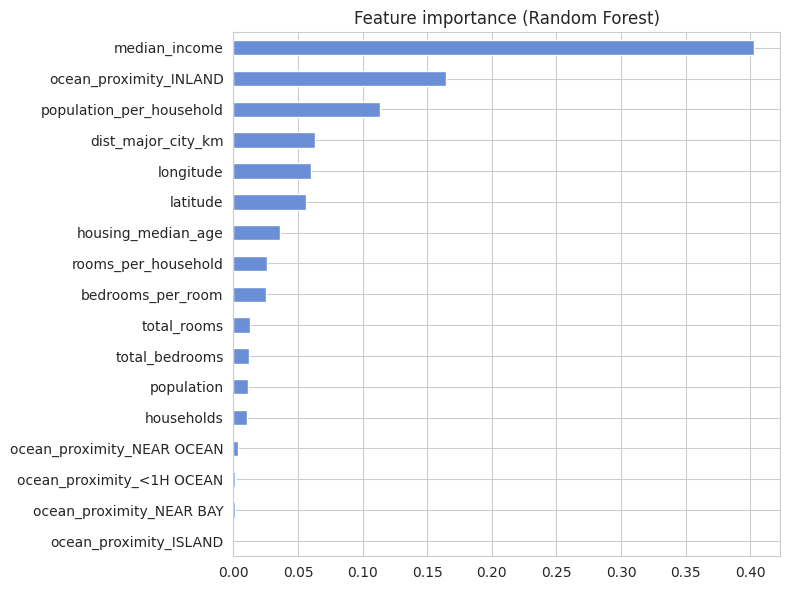


Highly correlated feature pairs:
('longitude', 'latitude', np.float64(0.93))
('total_rooms', 'total_bedrooms', np.float64(0.93))
('total_rooms', 'population', np.float64(0.87))
('total_rooms', 'households', np.float64(0.93))
('total_bedrooms', 'population', np.float64(0.88))
('total_bedrooms', 'households', np.float64(0.98))
('population', 'households', np.float64(0.91))


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv(f"{PROJECT_DIR}/housing_clean.csv")
target = "median_house_value"

# 1. new features
df["rooms_per_household"]       = df["total_rooms"] / df["households"]
df["bedrooms_per_room"]         = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"]  = df["population"] / df["households"]

CITIES = {"Los Angeles": (34.05, -118.24), "San Francisco": (37.77, -122.42),
          "San Diego": (32.72, -117.16), "San Jose": (37.34, -121.89)}
def km(lat, lon, c):                                   # haversine distance in km
    la1, lo1, la2, lo2 = map(np.radians, [lat, lon, c[0], c[1]])
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
df["dist_major_city_km"] = np.min([km(df["latitude"], df["longitude"], c) for c in CITIES.values()], axis=0)

print(df[["rooms_per_household", "bedrooms_per_room", "population_per_household", "dist_major_city_km"]].describe().round(2).T, "\n")

# 2. remove impossible blocks (extreme ratios)
before = len(df)
df = df[(df["rooms_per_household"] <= 20) & (df["population_per_household"] <= 10)].reset_index(drop=True)
print(f"Removed {before - len(df)} extreme blocks -> {len(df)} rows remain\n")

# 3. stratified 80/20 split (by income band), then save it
income_band = pd.qcut(df["median_income"], 5, labels=False)
train, test = train_test_split(df, test_size=0.2, stratify=income_band, random_state=42)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Median income  train {train['median_income'].median():.2f} | test {test['median_income'].median():.2f}")
print(f"Median price   train {train[target].median():,.0f} | test {test[target].median():,.0f}")
train.to_csv(f"{PROJECT_DIR}/train.csv", index=False)
test.to_csv(f"{PROJECT_DIR}/test.csv", index=False)

# 4. feature selection on the TRAINING set only
X = pd.get_dummies(train.drop(columns=target), columns=["ocean_proximity"], dtype=float)
X = X.fillna(X.median())                              # only for this ranking step
rf = RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=42).fit(X, train[target])
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print("\nFeature importance (Random Forest, training set):")
print(imp.sort_values(ascending=False).round(4).to_string())

plt.figure(figsize=(8, 6))
imp.plot.barh(color="#6b8fd6")
plt.title("Feature importance (Random Forest)")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/feature_importance.png", dpi=150)
plt.show()

# 5. features that overlap strongly (correlation above 0.8)
c = X.corr().abs()
pairs = [(a, b, round(c.loc[a, b], 2)) for i, a in enumerate(c.columns) for b in c.columns[i + 1:] if c.loc[a, b] > 0.8]
print("\nHighly correlated feature pairs:")
for p in pairs: print(p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
done: Baseline (predict the mean)
done: Linear Regression
done: Ridge Regression
done: Decision Tree
done: Random Forest
done: Gradient Boosting
done: Random Forest (all 14 features)

Cross-validation on the training set (5-fold):
                          Model  RMSE ($)  RMSE std   MAE ($)     R2
              Gradient Boosting 42227.535  1186.289 28487.850  0.814
                  Random Forest 43951.198  1256.440 29038.935  0.799
Random Forest (all 14 features) 44098.946  1298.999 29402.437  0.797
                  Decision Tree 57997.960   887.467 37956.943  0.649
              Linear Regression 58635.098  1383.991 42965.566  0.641
               Ridge Regression 58635.876  1384.837 42969.536  0.641
    Baseline (predict the mean) 97934.484  1102.193 78535.787 -0.000


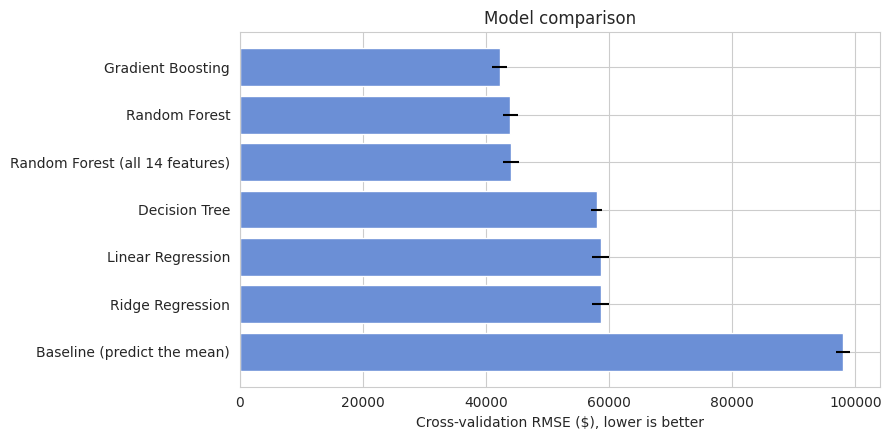

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

PROJECT_DIR = "/content/drive/MyDrive/housing_project"
target = "median_house_value"
train = pd.read_csv(f"{PROJECT_DIR}/train.csv")

# selected features (14 -> 9 columns): the raw count columns are dropped, the ratios stay
NUM = ["median_income", "housing_median_age", "rooms_per_household", "bedrooms_per_room",
       "population_per_household", "dist_major_city_km", "longitude", "latitude"]
CAT = ["ocean_proximity"]
ALL_NUM = NUM + ["total_rooms", "total_bedrooms", "population", "households"]
y = train[target]

def pipe(model, num):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return make_pipeline(pre, model)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

candidates = {
    "Baseline (predict the mean)":        (DummyRegressor(), NUM),
    "Linear Regression":                  (LinearRegression(), NUM),
    "Ridge Regression":                   (Ridge(alpha=1.0), NUM),
    "Decision Tree":                      (DecisionTreeRegressor(max_depth=12, random_state=42), NUM),
    "Random Forest":                      (RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42), NUM),
    "Gradient Boosting":                  (HistGradientBoostingRegressor(random_state=42), NUM),
    "Random Forest (all 14 features)":    (RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42), ALL_NUM),
}

rows = []
for name, (model, cols) in candidates.items():
    r = cross_validate(pipe(model, cols), train[cols + CAT], y, cv=cv, scoring=scoring)
    rows.append((name, -r["test_rmse"].mean(), r["test_rmse"].std(), -r["test_mae"].mean(), r["test_r2"].mean()))
    print(f"done: {name}")

res = pd.DataFrame(rows, columns=["Model", "RMSE ($)", "RMSE std", "MAE ($)", "R2"]).sort_values("RMSE ($)").reset_index(drop=True)
print("\nCross-validation on the training set (5-fold):")
print(res.round(3).to_string(index=False))
res.to_csv(f"{PROJECT_DIR}/cv_results.csv", index=False)

plt.figure(figsize=(9, 4.5))
plt.barh(res["Model"][::-1], res["RMSE ($)"][::-1], xerr=res["RMSE std"][::-1], color="#6b8fd6")
plt.xlabel("Cross-validation RMSE ($), lower is better"); plt.title("Model comparison")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/model_comparison.png", dpi=150)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 0}
CV RMSE after tuning: 40,966  (before tuning: 42,228)

Test RMSE : $39,985
Test MAE  : $26,402
Test R2   : 0.8303
Median absolute error: 10.3% of the true price
Baseline test RMSE (always predict the training mean): $97,079

Permutation importance (increase in RMSE when the feature is shuffled):
longitude                   35974.0
latitude                    28272.0
dist_major_city_km          25670.0
median_income               22511.0
population_per_household    14207.0
ocean_proximity             13768.0
rooms_per_household          7434.0
housing_median_age           4704.0
bedrooms_per_room            2985.0


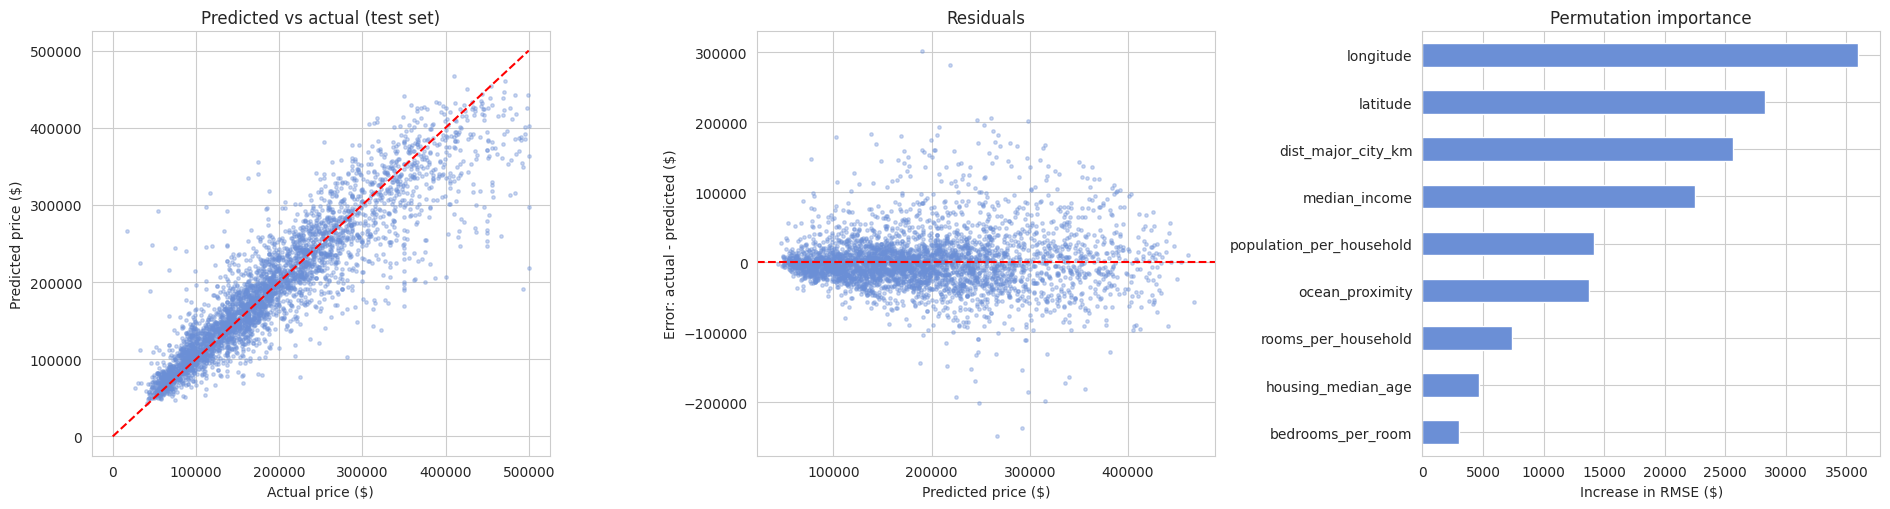

Saved the model to Drive.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

PROJECT_DIR = "/content/drive/MyDrive/housing_project"
target = "median_house_value"
train = pd.read_csv(f"{PROJECT_DIR}/train.csv")
test  = pd.read_csv(f"{PROJECT_DIR}/test.csv")

NUM = ["median_income", "housing_median_age", "rooms_per_household", "bedrooms_per_room",
       "population_per_household", "dist_major_city_km", "longitude", "latitude"]
CAT = ["ocean_proximity"]
X_train, y_train = train[NUM + CAT], train[target]
X_test,  y_test  = test[NUM + CAT],  test[target]

pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
pipe = make_pipeline(pre, HistGradientBoostingRegressor(random_state=42))

# 1. tune on the training set only (randomized search, 5-fold cross-validation)
params = {
    "histgradientboostingregressor__learning_rate":     [0.03, 0.05, 0.1],
    "histgradientboostingregressor__max_iter":          [200, 400, 600],
    "histgradientboostingregressor__max_leaf_nodes":    [15, 31, 63],
    "histgradientboostingregressor__min_samples_leaf":  [20, 40, 80],
    "histgradientboostingregressor__l2_regularization": [0, 1, 10],
}
search = RandomizedSearchCV(pipe, params, n_iter=20, cv=KFold(5, shuffle=True, random_state=42),
                            scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=42, verbose=1)
search.fit(X_train, y_train)
print("Best settings:", {k.split("__")[1]: v for k, v in search.best_params_.items()})
print(f"CV RMSE after tuning: {-search.best_score_:,.0f}  (before tuning: 42,228)\n")

# 2. the tuned model is tested ONCE on the unseen test blocks
model = search.best_estimator_
pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Test RMSE : ${rmse:,.0f}")
print(f"Test MAE  : ${mean_absolute_error(y_test, pred):,.0f}")
print(f"Test R2   : {r2_score(y_test, pred):.4f}")
print(f"Median absolute error: {np.median(np.abs(y_test - pred) / y_test) * 100:.1f}% of the true price")
print(f"Baseline test RMSE (always predict the training mean): ${np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))):,.0f}")

# 3. plots: predicted vs actual, residuals, permutation importance on the test set
imp = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error",
                             n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
print("\nPermutation importance (increase in RMSE when the feature is shuffled):")
print(imp.sort_values(ascending=False).round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
ax[0].scatter(y_test, pred, s=6, alpha=0.35, color="#6b8fd6")
ax[0].plot([0, 500000], [0, 500000], "r--"); ax[0].set_xlabel("Actual price ($)"); ax[0].set_ylabel("Predicted price ($)")
ax[0].set_title("Predicted vs actual (test set)")
res = y_test - pred
ax[1].scatter(pred, res, s=6, alpha=0.35, color="#6b8fd6"); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted price ($)"); ax[1].set_ylabel("Error: actual - predicted ($)"); ax[1].set_title("Residuals")
imp.plot.barh(ax=ax[2], color="#6b8fd6"); ax[2].set_xlabel("Increase in RMSE ($)"); ax[2].set_title("Permutation importance")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/test_evaluation.png", dpi=150)
plt.show()

# 4. save the model
joblib.dump({"model": model, "num": NUM, "cat": CAT}, f"{PROJECT_DIR}/housing_model.joblib")
print("Saved the model to Drive.")

In [1]:
from google.colab import drive, output
drive.mount('/content/drive')

import json
import numpy as np, pandas as pd, joblib
from IPython.display import HTML, JSON, display
from sklearn.metrics import mean_absolute_error

PROJECT_DIR = "/content/drive/MyDrive/housing_project"
saved = joblib.load(f"{PROJECT_DIR}/housing_model.joblib")
model, NUM, CAT = saved["model"], saved["num"], saved["cat"]
train = pd.read_csv(f"{PROJECT_DIR}/train.csv")
test  = pd.read_csv(f"{PROJECT_DIR}/test.csv")
target = "median_house_value"
MAE = float(mean_absolute_error(test[target], model.predict(test[NUM + CAT])))   # typical error, from the test set

# ---------- Python side: the saved model answers each request from the page ----------
CITIES = {"Los Angeles": (34.05, -118.24), "San Francisco": (37.77, -122.42),
          "San Diego": (32.72, -117.16), "San Jose": (37.34, -121.89)}
def km(lat, lon, c):                                   # haversine distance in km
    la1, lo1, la2, lo2 = map(np.radians, [lat, lon, c[0], c[1]])
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def predict_house(payload):
    try:
        v = json.loads(payload)
        row = {k: float(v[k]) for k in ["median_income", "housing_median_age", "rooms_per_household",
                                        "bedrooms_per_room", "population_per_household", "latitude", "longitude"]}
        row["dist_major_city_km"] = float(min(km(row["latitude"], row["longitude"], c) for c in CITIES.values()))
        row["ocean_proximity"] = v["ocean_proximity"]
        price = float(model.predict(pd.DataFrame([row])[NUM + CAT])[0])
        return JSON({"price": price, "dist_km": row["dist_major_city_km"]})
    except Exception as e:
        return JSON({"error": str(e)})

output.register_callback("housing.predict", predict_house)

# ---------- data for the page: slider ranges, defaults, and a sample of blocks for the map ----------
allb = pd.concat([train, test], ignore_index=True)
CATS = ["<1H OCEAN", "INLAND", "NEAR OCEAN", "NEAR BAY"]
sample = allb[allb["ocean_proximity"].isin(CATS)].sample(1600, random_state=1)
PTS = [[round(r.longitude, 2), round(r.latitude, 2), int(r[target]), CATS.index(r.ocean_proximity)] for _, r in sample.iterrows()]

def rng(c, step):
    lo, hi = np.floor(train[c].quantile(0.01) / step) * step, np.ceil(train[c].quantile(0.99) / step) * step
    return [round(float(lo), 2), round(float(hi), 2), step, round(float(train[c].median()), 2)]
RANGES = {"median_income": rng("median_income", 0.1), "housing_median_age": rng("housing_median_age", 1),
          "rooms_per_household": rng("rooms_per_household", 0.1), "bedrooms_per_room": rng("bedrooms_per_room", 0.01),
          "population_per_household": rng("population_per_household", 0.1)}
PLACES = {"San Francisco": [37.77, -122.42, 3], "Oakland": [37.80, -122.27, 3], "San Jose": [37.34, -121.89, 0],
          "Los Angeles": [34.05, -118.24, 0], "Santa Monica": [34.02, -118.49, 2], "San Diego": [32.72, -117.16, 2],
          "Santa Barbara": [34.42, -119.70, 2], "Sacramento": [38.58, -121.49, 1], "Fresno": [36.74, -119.79, 1],
          "Bakersfield": [35.37, -119.02, 1], "Riverside": [33.95, -117.40, 1], "Lake Tahoe": [39.17, -120.14, 1]}
DATA = {"pts": PTS, "ranges": RANGES, "places": PLACES, "cats": CATS, "mae": MAE}

# ---------- Browser side: layout, sliders, clickable map ----------
UI = r"""
<style>
#hp{--ink:#1f2937;--mut:#6b7280;--line:#e5e7eb;--bg:#f6f7fb;
 font-family:-apple-system,Segoe UI,Roboto,Arial,sans-serif;color:#1f2937;background:var(--bg);border-radius:14px;padding:18px;max-width:960px;box-sizing:border-box}
#hp *{box-sizing:border-box}
#hp h1{margin:0;font-size:22px;font-weight:700;color:#1f2937 !important}
#hp .sub{color:var(--mut);font-size:13px;margin:4px 0 16px}
#hp .grid{display:grid;grid-template-columns:1fr 1fr;gap:14px}
@media(max-width:760px){#hp .grid{grid-template-columns:1fr}}
#hp .card{background:#fff;border:1px solid var(--line);border-radius:12px;padding:16px}
#hp .card h2{margin:0 0 12px;font-size:12px;letter-spacing:.06em;text-transform:uppercase;color:var(--mut) !important;font-weight:600}
#hp .row{margin-bottom:12px}
#hp .row .top{display:flex;justify-content:space-between;font-size:13.5px;margin-bottom:3px;color:#1f2937}
#hp .row .top b{font-variant-numeric:tabular-nums}
#hp input[type=range]{width:100%;accent-color:#4f46e5}
#hp select{width:100%;padding:7px 8px;border:1px solid var(--line);border-radius:8px;font-size:13.5px;background:#fff;color:#1f2937}
#hp .two{display:grid;grid-template-columns:1fr 1fr;gap:10px;margin-bottom:12px}
#hp .two label{font-size:12px;color:var(--mut);display:block;margin-bottom:3px}
#hp .presets{display:flex;flex-wrap:wrap;gap:8px;margin-top:4px}
#hp .presets button{border:1px solid var(--line);background:#fff;border-radius:999px;padding:6px 12px;font-size:12.5px;cursor:pointer;color:#1f2937}
#hp .presets button:hover{background:#f3f4f6}
#hp .price{font-size:38px;font-weight:700;line-height:1.1;font-variant-numeric:tabular-nums;color:#1f2937}
#hp .lab{font-size:12px;color:var(--mut);margin-bottom:2px}
#hp .range{font-size:13.5px;color:#374151;margin:6px 0 10px}
#hp .scale{position:relative;height:14px;background:#eef0f4;border-radius:7px;margin:10px 0 4px}
#hp .scale .band{position:absolute;top:0;height:100%;background:#c7d2fe;border-radius:7px}
#hp .scale .mark{position:absolute;top:-4px;width:4px;height:22px;background:#4f46e5;border-radius:2px}
#hp .ticks{display:flex;justify-content:space-between;font-size:11px;color:var(--mut)}
#hp .note{font-size:12.5px;color:#92400e;background:#fffbeb;border:1px solid #fde68a;border-radius:8px;padding:7px 10px;margin-top:10px;display:none}
#hp .facts{font-size:12.5px;color:#374151;margin-top:10px;line-height:1.6}
#hp .legend{display:flex;align-items:center;gap:8px;font-size:11.5px;color:var(--mut);justify-content:center;margin-top:6px}
#hp .legend .grad{width:160px;height:9px;border-radius:5px}
#hp .foot{font-size:11.5px;color:var(--mut);margin-top:12px}
#hp svg text{font-family:inherit}
</style>
<div id="hp">
  <h1>California House Price Estimator</h1>
  <div class="sub">Gradient Boosting model trained on 1990 California census blocks &middot; predicts the median house value of a block</div>
  <div class="grid">
    <div class="card">
      <h2>Block characteristics</h2>
      <div id="hp-sl"></div>
      <h2 style="margin-top:4px">Try an example</h2>
      <div class="presets" id="hp-pre"></div>
    </div>
    <div class="card">
      <h2>Estimated median house value</h2>
      <div class="lab">Prediction</div>
      <div class="price" id="hp-price">...</div>
      <div class="range" id="hp-range">&nbsp;</div>
      <div class="scale"><div class="band" id="hp-band"></div><div class="mark" id="hp-mark"></div></div>
      <div class="ticks"><span>$0</span><span>$100k</span><span>$200k</span><span>$300k</span><span>$400k</span><span>$500k</span></div>
      <div class="facts" id="hp-facts"></div>
      <div class="note" id="hp-note"></div>
    </div>
  </div>
  <div class="card" style="margin-top:14px">
    <h2>Location: pick a place, move the sliders, or click the map</h2>
    <div class="two">
      <div><label>Place</label><select id="hp-place"></select></div>
      <div><label>Location type</label><select id="hp-cat"></select></div>
    </div>
    <div class="grid" style="grid-template-columns:1fr 1fr;gap:10px 14px">
      <div class="row"><div class="top"><span>Latitude</span><b id="hp-latv"></b></div><input type="range" id="hp-lat" min="32.5" max="42" step="0.01"></div>
      <div class="row"><div class="top"><span>Longitude</span><b id="hp-lonv"></b></div><input type="range" id="hp-lon" min="-124.4" max="-114.3" step="0.01"></div>
    </div>
    <svg id="hp-map" viewBox="0 0 460 470" width="100%" style="max-width:460px;display:block;margin:6px auto 0;cursor:crosshair"></svg>
    <div class="legend"><span>$50k</span><div class="grad" id="hp-grad"></div><span>$500k</span></div>
  </div>
  <div class="foot">Educational project based on 1990 census data: not a valuation tool. The range shown is the model's typical error on unseen blocks.</div>
</div>
<script>
(function(){
  const D = __DATA__;
  const $ = id => document.getElementById(id);
  const LAB = {median_income:["Median income (x $10,000)",v=>"$"+(v*10).toFixed(0)+"k"],housing_median_age:["Median house age",v=>v+" yrs"],
    rooms_per_household:["Rooms per household",v=>v.toFixed(1)],bedrooms_per_room:["Bedrooms per room",v=>v.toFixed(2)],
    population_per_household:["People per household",v=>v.toFixed(1)]};
  const val = {}, sl = {}, vl = {};
  let lat = 37.77, lon = -122.42, cat = 3;

  // feature sliders
  Object.keys(D.ranges).forEach(k=>{
    const r = D.ranges[k]; val[k]=r[3];
    const row=document.createElement("div"); row.className="row";
    row.innerHTML='<div class="top"><span>'+LAB[k][0]+'</span><b></b></div><input type="range">';
    const inp=row.querySelector("input"); inp.min=r[0]; inp.max=r[1]; inp.step=r[2]; inp.value=r[3];
    sl[k]=inp; vl[k]=row.querySelector("b");
    inp.addEventListener("input",()=>{val[k]=parseFloat(inp.value); update();});
    $("hp-sl").appendChild(row);
  });
  // selects
  D.cats.forEach((c,i)=>{const o=document.createElement("option"); o.value=i; o.textContent=c; $("hp-cat").appendChild(o);});
  const names=Object.keys(D.places).concat(["Custom location"]);
  names.forEach(n=>{const o=document.createElement("option"); o.textContent=n; $("hp-place").appendChild(o);});

  // map
  const W=460,H=470,PX=14,PY=12, LO=[-124.6,-113.9], LA=[32.3,42.2];
  const X=l=>PX+(l-LO[0])/(LO[1]-LO[0])*(W-2*PX), Y=a=>H-PY-(a-LA[0])/(LA[1]-LA[0])*(H-2*PY);
  const IX=x=>LO[0]+(x-PX)/(W-2*PX)*(LO[1]-LO[0]), IY=y=>LA[0]+(H-PY-y)/(H-2*PY)*(LA[1]-LA[0]);
  const STOPS=[[50e3,[59,47,122]],[150e3,[42,122,176]],[250e3,[63,181,154]],[350e3,[182,216,106]],[500e3,[244,224,77]]];
  function col(p){ if(p<=STOPS[0][0]) return "rgb("+STOPS[0][1]+")"; for(let i=1;i<STOPS.length;i++){ if(p<=STOPS[i][0]){const a=STOPS[i-1],b=STOPS[i],t=(p-a[0])/(b[0]-a[0]); return "rgb("+a[1].map((c,j)=>Math.round(c+(b[1][j]-c)*t)).join(",")+")";}} return "rgb("+STOPS[4][1]+")"; }
  $("hp-grad").style.background="linear-gradient(90deg,"+STOPS.map(s=>"rgb("+s[1]+")").join(",")+")";
  let g=""; D.pts.forEach(p=>{g+='<circle cx="'+X(p[0]).toFixed(1)+'" cy="'+Y(p[1]).toFixed(1)+'" r="2.6" fill="'+col(p[2])+'" fill-opacity=".75"/>';});
  g+='<g id="hp-me"><circle r="11" fill="#fff" fill-opacity=".85" stroke="#111" stroke-width="2.2"/><circle r="3" fill="#111"/></g>';
  $("hp-map").innerHTML=g;

  function nearest(){ let b=1e9,bc=cat; D.pts.forEach(p=>{const d=(p[0]-lon)**2+(p[1]-lat)**2; if(d<b){b=d;bc=p[3];}}); return [Math.sqrt(b),bc]; }
  function setLoc(a,o,c,place){ lat=a; lon=o; if(c!==null) cat=c; else cat=nearest()[1]; $("hp-lat").value=lat; $("hp-lon").value=lon; $("hp-cat").value=cat; $("hp-place").value=place; update(); }

  $("hp-place").onchange=e=>{const n=e.target.value; if(D.places[n]) setLoc(D.places[n][0],D.places[n][1],D.places[n][2],n);};
  $("hp-cat").onchange=e=>{cat=parseInt(e.target.value); update();};
  $("hp-lat").oninput=e=>setLoc(parseFloat(e.target.value),lon,null,"Custom location");
  $("hp-lon").oninput=e=>setLoc(lat,parseFloat(e.target.value),null,"Custom location");
  $("hp-map").addEventListener("click",ev=>{const r=$("hp-map").getBoundingClientRect(); const sx=W/r.width, sy=H/r.height;
    setLoc(Math.round(IY((ev.clientY-r.top)*sy)*100)/100, Math.round(IX((ev.clientX-r.left)*sx)*100)/100, null, "Custom location");});

  // examples
  const EX={"Bay Area home":["San Francisco",{median_income:7.5,housing_median_age:30,rooms_per_household:5.5,bedrooms_per_room:0.2,population_per_household:2.8}],
    "Inland family home":["Fresno",{median_income:3.0,housing_median_age:25,rooms_per_household:5.0,bedrooms_per_room:0.22,population_per_household:3.2}],
    "Coastal Los Angeles":["Santa Monica",{median_income:6.0,housing_median_age:35,rooms_per_household:5.0,bedrooms_per_room:0.2,population_per_household:2.6}],
    "Modest rural block":["Lake Tahoe",{median_income:2.2,housing_median_age:20,rooms_per_household:5.5,bedrooms_per_room:0.23,population_per_household:2.9}]};
  Object.keys(EX).forEach(n=>{const b=document.createElement("button"); b.textContent=n;
    b.onclick=()=>{Object.keys(EX[n][1]).forEach(k=>{val[k]=EX[n][1][k]; sl[k].value=val[k];}); const p=D.places[EX[n][0]]; setLoc(p[0],p[1],p[2],EX[n][0]);};
    $("hp-pre").appendChild(b);});

  const fmt=v=>"$"+Math.round(v/100)*100;
  const k=v=>"$"+Math.round(v/1000)+"k";
  let seq=0;
  function update(){
    Object.keys(val).forEach(f=>{vl[f].textContent=LAB[f][1](val[f]);});
    $("hp-latv").textContent=lat.toFixed(2); $("hp-lonv").textContent=lon.toFixed(2);
    $("hp-me").setAttribute("transform","translate("+X(lon)+","+Y(lat)+")");
    const my=++seq;
    const payload=Object.assign({},val,{latitude:lat,longitude:lon,ocean_proximity:D.cats[cat]});
    google.colab.kernel.invokeFunction("housing.predict",[JSON.stringify(payload)],{}).then(res=>{
      if(my!==seq) return;
      const d=res.data["application/json"];
      if(d.error){$("hp-price").textContent="Error"; $("hp-range").textContent=d.error; return;}
      const p=d.price, lo=Math.max(0,p-D.mae), hi=p+D.mae;
      $("hp-price").textContent="$"+(Math.round(p/100)*100).toLocaleString("en-US");
      $("hp-range").textContent="Typical error: about ±$"+Math.round(D.mae/1000)+"k  →  "+k(lo)+" to "+k(hi);
      const pc=v=>Math.min(100,Math.max(0,v/5e5*100));
      $("hp-band").style.left=pc(lo)+"%"; $("hp-band").style.width=(pc(hi)-pc(lo))+"%"; $("hp-mark").style.left="calc("+pc(p)+"% - 2px)";
      $("hp-facts").innerHTML="Location type: <b>"+D.cats[cat]+"</b><br>Distance to the nearest major city (LA, SF, San Diego, San Jose): <b>"+d.dist_km.toFixed(0)+" km</b>";
      const nn=nearest()[0], notes=[];
      if(p>350000) notes.push("Estimates above about $350k are less reliable: the model had few expensive blocks to learn from, and blocks priced at $500k or more were removed.");
      if(nn>0.5) notes.push("This spot is far from any block in the dataset, so the estimate is a guess.");
      const nb=$("hp-note"); nb.style.display=notes.length?"block":"none"; nb.textContent=notes.join(" ");
    });
  }
  setLoc(37.77,-122.42,3,"San Francisco");
})();
</script>
"""
display(HTML(UI.replace("__DATA__", json.dumps(DATA))))

Mounted at /content/drive
